# 1. EDA - исследовательский анализ данных

Загружаем датасет, смотрим структуру, распределения таргета и массы,
проверяем наличие изображений.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
import sys

PROJECT_DIR = '/content/drive/MyDrive/calorie-project'
os.chdir(PROJECT_DIR)
sys.path.append(PROJECT_DIR)

print("Рабочая директория:", os.getcwd())
print("Файлы в корне проекта:", os.listdir('.'))

Mounted at /content/drive
Рабочая директория: /content/drive/MyDrive/calorie-project
Файлы в корне проекта: ['scripts', 'data', 'README.md', '.gitignore', 'best_calorie_model.pth', 'notebook.ipynb', 'requirements.txt', 'Копия блокнота "notebook.ipynb"']


In [5]:
import os

img_dir = '/content/images'
if os.path.exists(img_dir):
    folders = os.listdir(img_dir)
    print(f"Отлично! Картинки на месте. Папок: {len(folders)}")
    print("Примеры:", folders[:3])
else:
    print("Картинок нет. Нужно запустить ячейку распаковки.")

Картинок нет. Нужно запустить ячейку распаковки.


In [6]:
import os, zipfile, time

zip_path = '/content/drive/MyDrive/calorie-project/data/images.zip'
dst_dir  = '/content'

print("Начинаю распаковку...")
t0 = time.time()
with zipfile.ZipFile(zip_path, 'r') as zf:
    zf.extractall(dst_dir)
print(f"Готово за {time.time()-t0:.0f} сек")
print("Папок с картинками в /content/images:", len(os.listdir('/content/images')))

Начинаю распаковку...
Готово за 39 сек
Папок с картинками в /content/images: 3490


In [7]:
import os
import pandas as pd
import numpy as np

DATA_DIR = 'data'

dish = pd.read_csv(os.path.join(DATA_DIR, 'dish.csv'))
ingr = pd.read_csv(os.path.join(DATA_DIR, 'ingredients.csv'))

print("=== dish.csv ===")
print("форма:", dish.shape)
print("колонки:", list(dish.columns))
print("\nтипы данных:")
print(dish.dtypes)
print("\nпропуски:")
print(dish.isna().sum())

print("\n=== ingredients.csv ===")
print("форма:", ingr.shape)
print("колонки:", list(ingr.columns))
print(ingr.head(3))

print("\n=== split ===")
print(dish['split'].value_counts())

=== dish.csv ===
форма: (3262, 5)
колонки: ['dish_id', 'total_calories', 'total_mass', 'ingredients', 'split']

типы данных:
dish_id            object
total_calories    float64
total_mass        float64
ingredients        object
split              object
dtype: object

пропуски:
dish_id           0
total_calories    0
total_mass        0
ingredients       0
split             0
dtype: int64

=== ingredients.csv ===
форма: (555, 2)
колонки: ['id', 'ingr']
   id            ingr
0   1  cottage cheese
1   2    strawberries
2   3    garden salad

=== split ===
split
train    2755
test      507
Name: count, dtype: int64


In [8]:
import os, zipfile, time

src_dir  = '/content/drive/MyDrive/calorie-project/data/images'
zip_path = '/content/drive/MyDrive/calorie-project/data/images.zip'

if os.path.exists(zip_path):
    print("Архив уже есть:", zip_path, "размер:", os.path.getsize(zip_path)/1e9, "GB")
else:
    dish_ids = sorted(os.listdir(src_dir))
    t0 = time.time()
    with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_STORED) as zf:
        for i, dish_id in enumerate(dish_ids, 1):
            file_path = os.path.join(src_dir, dish_id, 'rgb.png')
            if os.path.exists(file_path):
                zf.write(file_path, f'images/{dish_id}/rgb.png')
            if i % 500 == 0:
                print(f"{i}/{len(dish_ids)} файлов ({time.time()-t0:.0f} сек)", flush=True)
    print(f"Готово за {time.time()-t0:.0f} сек. Размер: {os.path.getsize(zip_path)/1e9:.2f} GB")

Архив уже есть: /content/drive/MyDrive/calorie-project/data/images.zip размер: 1.454619269 GB


## 1.1. Распределение таргета и массы

Смотрим на `total_calories`, `total_mass` и производную плотность (ккал/100г).
Это определит стратегию нормализации и baseline.

=== Калории (total_calories) ===
count    2755.0
mean      254.9
std       221.0
min         0.0
1%          7.3
25%        81.8
50%       208.1
75%       376.6
99%       913.6
max      3943.3
Name: total_calories, dtype: float64

=== Масса (total_mass), граммы ===
count    2755.0
mean      218.0
std       163.1
min         5.0
1%         17.0
25%        94.0
50%       179.0
75%       308.0
99%       702.8
max      3051.0
Name: total_mass, dtype: float64

=== Очень калорийные блюда (top-10) ===
              dish_id  total_calories  total_mass
1287  dish_1560974769     3943.325195      3051.0
101   dish_1565033265     1324.084961       625.0
2321  dish_1562603895     1268.157349       517.0
959   dish_1564170010     1264.548340       831.0
1658  dish_1563476577     1238.033691       857.0
2394  dish_1563305083     1234.856323       901.0
2216  dish_1568401090     1158.989990       614.0
1213  dish_1558379876     1148.250977       374.0
2579  dish_1568318480     1119.280029       587.0


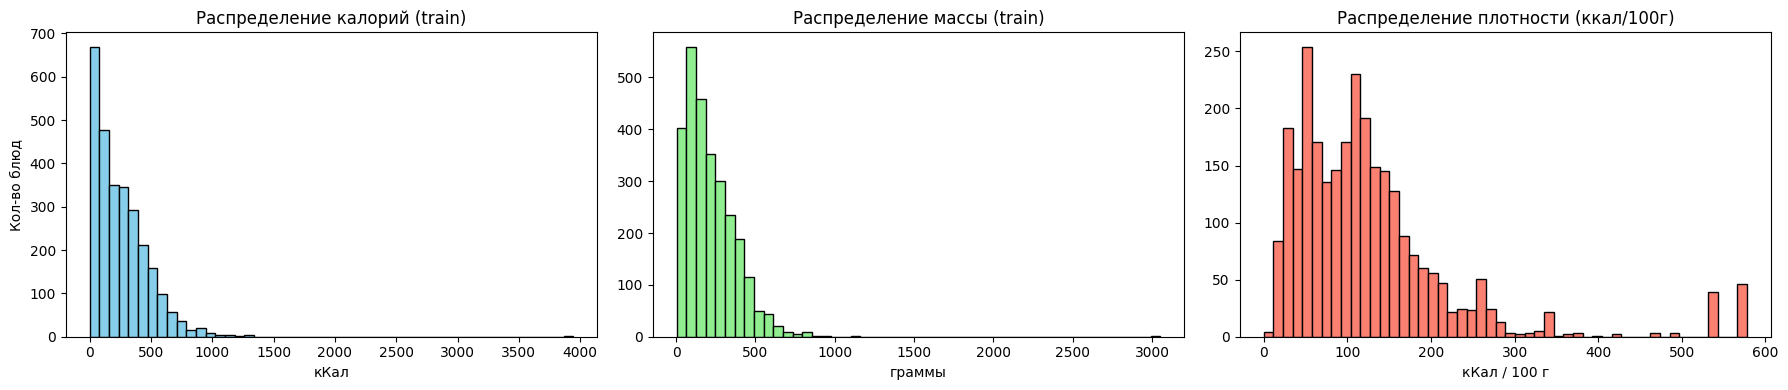


=== Плотность (ккал/100г) ===
count    2755.0
mean      128.0
std       103.8
min         0.0
1%         18.0
25%        59.2
50%       107.4
75%       154.6
99%       578.1
max       578.1
dtype: float64


In [9]:
import matplotlib.pyplot as plt

train = dish[dish['split'] == 'train'].reset_index(drop=True)
test = dish[dish['split'] == 'test'].reset_index(drop=True)

print("=== Калории (total_calories) ===")
print(train['total_calories'].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).round(1))

print("\n=== Масса (total_mass), граммы ===")
print(train['total_mass'].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).round(1))

print("\n=== Очень калорийные блюда (top-10) ===")
print(train.nlargest(10, 'total_calories')[['dish_id', 'total_calories', 'total_mass']])

print("\n=== Очень лёгкие блюда (bottom-10) ===")
print(train.nsmallest(10, 'total_calories')[['dish_id', 'total_calories', 'total_mass']])

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

axes[0].hist(train['total_calories'], bins=50, color='skyblue', edgecolor='black')
axes[0].set_title('Распределение калорий (train)')
axes[0].set_xlabel('кКал')
axes[0].set_ylabel('Кол-во блюд')

axes[1].hist(train['total_mass'], bins=50, color='lightgreen', edgecolor='black')
axes[1].set_title('Распределение массы (train)')
axes[1].set_xlabel('граммы')

density = train['total_calories'] / (train['total_mass'] + 1e-6) * 100
axes[2].hist(density, bins=50, color='salmon', edgecolor='black')
axes[2].set_title('Распределение плотности (ккал/100г)')
axes[2].set_xlabel('кКал / 100 г')

plt.tight_layout()
plt.show()

print("\n=== Плотность (ккал/100г) ===")
print(density.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).round(1))

#### Вывод из графиков и цифр:

- Распределения сильно смещены вправо (long-tail). Большинство блюд - до 500 ккал, но есть «монстры» вплоть до 3943 ккал (и масса у него 3051 г - это, скорее всего, ошибка разметки или гигантский стол на компанию).

- Есть странные блюда. Например, 0 ккал при массе 86 г, или 1.84 ккал при массе 8 г. Это, вероятно, специи, соусы или кусочки чего-то одного. Они будут давать высокую ошибку, но их немного.

- Плотность (ккал/100г) имеет интересный «горб» справа (около 500–600 ккал). Это орехи, масла, сыры. Модели будет полезно это выучить.

## 1.2. Baseline: предсказание медианы

Оцениваем MAE, если всегда предсказывать одно и то же число (медиану train).
Это наш минимальный порог: нейросеть обязана ошибаться меньше.

In [10]:
from sklearn.metrics import mean_absolute_error

# Медиана и среднее по train
median_cal = train['total_calories'].median()
mean_cal = train['total_calories'].mean()

print(f"Медиана train: {median_cal:.2f} кКал")
print(f"Среднее train: {mean_cal:.2f} кКал")

# Предсказываем медиану для теста
pred_median = np.full(len(test), median_cal)
mae_median = mean_absolute_error(test['total_calories'], pred_median)

# Предсказываем среднее для теста
pred_mean = np.full(len(test), mean_cal)
mae_mean = mean_absolute_error(test['total_calories'], pred_mean)

print(f"\nMAE на тесте (предсказываем медиану): {mae_median:.2f} кКал")
print(f"MAE на тесте (предсказываем среднее): {mae_mean:.2f} кКал")

Медиана train: 208.12 кКал
Среднее train: 254.93 кКал

MAE на тесте (предсказываем медиану): 167.34 кКал
MAE на тесте (предсказываем среднее): 168.52 кКал


**Вывод:** Медиана и среднее по train — 208 и 255 кКал. MAE при предсказании константы на тесте составляет ~167 кКал. Это наш базовый порог: любая обученная модель обязана ошибаться меньше 167 кКал, чтобы быть полезной.

## 1.3. Baseline: линейная регрессия по массе и предсказание плотности

Проверяем, сколько информации о калорийности несёт только масса блюда.
А также проверяем гипотезу: может быть, проще предсказывать не калории,
а плотность (ккал/г), а затем умножать на массу?

In [11]:
from sklearn.linear_model import LinearRegression

# Берем только признак массы
X_train_mass = train[['total_mass']]
y_train = train['total_calories']

X_test_mass = test[['total_mass']]
y_test = test['total_calories']

# Обучаем простую линейную регрессию
lr_mass = LinearRegression()
lr_mass.fit(X_train_mass, y_train)

# Предсказание
pred_mass = lr_mass.predict(X_test_mass)

# Оценка
mae_mass = mean_absolute_error(y_test, pred_mass)
print(f"MAE линейной регрессии только по массе: {mae_mass:.2f} кКал")
print(f"Коэффициент (сколько ккал добавляет 1 грамм): {lr_mass.coef_[0]:.4f}")

# --- Дополнительно: предсказание плотности ---
# Вычислим плотность в train (ккал / грамм)
train_density = train['total_calories'] / (train['total_mass'] + 1e-6)
median_density = train_density.median()

# Предсказываем: медианная плотность * масса
pred_density_baseline = median_density * test['total_mass']
mae_density_baseline = mean_absolute_error(y_test, pred_density_baseline)
print(f"\nMAE если предсказывать медианную плотность ({median_density:.3f} ккал/г) * масса: {mae_density_baseline:.2f} кКал")

MAE линейной регрессии только по массе: 104.57 кКал
Коэффициент (сколько ккал добавляет 1 грамм): 1.0434

MAE если предсказывать медианную плотность (1.074 ккал/г) * масса: 105.03 кКал


**Вывод:** Масса - сильный признак. Линейная регрессия по массе даёт MAE ~104.5 кКал (против 167 у константы). При этом предсказание медианной плотности * массу даёт практически идентичный результат (105 кКал), что подтверждает среднюю плотность блюд около 1.04 ккал/г. Для дальнейшей работы (с текстом и фото) нам нужно отнять этот базовый эффект массы, чтобы модель училась предсказывать именно отклонения от среднего.

## 1.4. Baseline: Только текст (TF-IDF + Ridge)

Проверяем, можно ли предсказать калорийность только по списку ингредиентов.
Сначала переводим ID ингредиентов в названия (маппинг), затем применяем
TF-IDF и линейную регрессию с L2-регуляризацией (Ridge).

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge

# 1. Маппинг ингредиентов: из ingr_123 в реальное название
ingr_mapping = dict(zip(ingr['id'], ingr['ingr']))

def map_ingredients(ingr_string):
    if pd.isna(ingr_string):
        return ""
    ids = ingr_string.split(';')
    names = []
    for raw in ids:
        raw = raw.strip()
        if not raw:
            continue
        num_str = raw.replace('ingr_', '')
        try:
            num = int(num_str)
        except ValueError:
            continue
        if num in ingr_mapping:
            names.append(ingr_mapping[num])
    return ", ".join(names)

# Применяем к train и test
train['ingredients_clean'] = train['ingredients'].apply(map_ingredients)
test['ingredients_clean'] = test['ingredients'].apply(map_ingredients)

print("Пример восстановленного текста:")
print(train[['ingredients_clean']].head(3))

# 2. TF-IDF
vectorizer = TfidfVectorizer(max_features=1000)
X_train_tfidf = vectorizer.fit_transform(train['ingredients_clean'])
X_test_tfidf = vectorizer.transform(test['ingredients_clean'])

# 3. Ridge регрессия
ridge = Ridge(alpha=1.0)
ridge.fit(X_train_tfidf, train['total_calories'])

pred_ridge = ridge.predict(X_test_tfidf)
mae_ridge = mean_absolute_error(test['total_calories'], pred_ridge)

print(f"\nMAE текстовой модели (TF-IDF + Ridge): {mae_ridge:.2f} кКал")

Пример восстановленного текста:
                                   ingredients_clean
0  pepper, white rice, mixed greens, garlic, soy ...
1           cherry tomatoes, cucumbers, baby carrots
2                                         deprecated

MAE текстовой модели (TF-IDF + Ridge): 106.09 кКал


**Вывод:** Текстовая модель (TF-IDF + Ridge) достигла MAE ~106 кКал, что сопоставимо с точностью только по массе (104.5 кКал). Это говорит о том, что состав блюда (ингредиенты) несёт в себе много информации о калорийности, и объединение текста и массы даст лучший результат.

## 1.5. Baseline: Масса + Текст (TF-IDF + Ridge)

Объединяем наши лучшие признаки (массу и текстовое описание) в единую
матрицу и обучаем Ridge-регрессию. Ожидаем, что MAE упадёт ниже 100 кКал.

In [13]:
import scipy.sparse as sp

# Объединяем TF-IDF матрицу и массу
# (переводим массу в разреженный формат, чтобы объединить с TF-IDF)
mass_train = sp.csr_matrix(train['total_mass'].values.reshape(-1, 1))
mass_test = sp.csr_matrix(test['total_mass'].values.reshape(-1, 1))

X_train_combined = sp.hstack([X_train_tfidf, mass_train])
X_test_combined = sp.hstack([X_test_tfidf, mass_test])

# Обучаем Ridge на объединенных признаках
ridge_combined = Ridge(alpha=1.0)
ridge_combined.fit(X_train_combined, train['total_calories'])

pred_combined = ridge_combined.predict(X_test_combined)
mae_combined = mean_absolute_error(test['total_calories'], pred_combined)

print(f"MAE (Масса + Текст, Ridge): {mae_combined:.2f} кКал")

MAE (Масса + Текст, Ridge): 67.45 кКал


**Вывод:** Объединение массы и текста дало MAE 67.45 кКал. Это подтверждает, что признаки отлично дополняют друг друга. Линейная модель уже близка к целевой метрике, а нейросеть с картинками должна легко преодолеть порог в 50 кКал.

## 2.1. Конфигурация обучения (config.py)

Создаем файл с гиперпараметрами. Пути относительные, чтобы ноутбук работал
и на локальной машине, и в Colab.

In [14]:
%%writefile scripts/config.py
import torch

class Config:
    def __init__(self):
        self.SEED = 42
        self.MODEL_SAVE_PATH = 'best_calorie_model.pth'

        # Ингредиенты на английском -> используем английский BERT
        self.TEXT_MODEL = 'distilbert-base-uncased'
        self.IMAGE_MODEL = 'efficientnet_b0'

        self.IMG_SIZE = 224
        self.MAX_LENGTH = 64
        self.HIDDEN_DIM = 256

        self.BATCH_SIZE = 16
        self.EPOCHS = 20
        self.WEIGHT_DECAY = 1e-2

        # Доля валидации, которую выделяем из train для early stopping
        self.VAL_SPLIT = 0.15

        self.TEXT_LR = 1e-5
        self.IMAGE_LR = 1e-4
        self.CLASSIFIER_LR = 1e-3

        self.TARGET_MEAN = None
        self.TARGET_STD = None
        self.MASS_MEAN = None
        self.MASS_STD = None

        self.DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

Overwriting scripts/config.py


In [15]:
import os
print("config.py существует:", os.path.exists('scripts/config.py'))
with open('scripts/config.py', 'r') as f:
    print(f.read()[:200], "...")

config.py существует: True
import torch

class Config:
    def __init__(self):
        self.SEED = 42
        self.MODEL_SAVE_PATH = 'best_calorie_model.pth'

        # Ингредиенты на английском -> используем английский BERT
   ...


## 2.2. Загрузчик данных и аугментации (dataset.py)

Класс `DishDataset` загружает картинку по `dish_id`, токенизирует список
ингредиентов и нормализует массу с калориями. Для тренировочных данных
применяем аугментации (обрезка, поворот, изменение цвета), чтобы модель
не переобучалась.

In [16]:
%%writefile scripts/dataset.py
import os
import numpy as np
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2


class DishDataset(Dataset):
    def __init__(self, df, images_dir="data/images", transform=None,
                 tokenizer=None, max_length=64,
                 target_mean=0.0, target_std=1.0,
                 mass_mean=0.0, mass_std=1.0):
        self.df = df.reset_index(drop=True)
        self.images_dir = images_dir
        self.transform = transform
        self.tokenizer = tokenizer
        self.max_length = max_length
        self.target_mean = target_mean
        self.target_std = target_std
        self.mass_mean = mass_mean
        self.mass_std = mass_std

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        dish_id = row['dish_id']

        img_path = os.path.join(self.images_dir, str(dish_id), "rgb.png")
        if os.path.exists(img_path):
            with Image.open(img_path) as img:
                image = np.array(img.convert("RGB"))
        else:
            image = np.zeros((224, 224, 3), dtype=np.uint8)

        if self.transform:
            image = self.transform(image=image)['image']

        ingredients = row['ingredients_clean']
        text_input = str(ingredients) if pd.notna(ingredients) else ""

        if self.tokenizer:
            text_encoded = self.tokenizer(
                text_input, padding='max_length', truncation=True,
                max_length=self.max_length, return_tensors="pt"
            )
            text_features = {k: v.squeeze(0).clone() for k, v in text_encoded.items()}
        else:
            text_features = text_input

        mass_val = row['total_mass']
        total_cal = row['total_calories']
        mass_val = mass_val if pd.notna(mass_val) else 0.0
        total_cal = total_cal if pd.notna(total_cal) else 0.0

        # СЧИТАЕМ ПЛОТНОСТЬ (ккал на 100 г) вместо чистых калорий
        density_val = total_cal / (mass_val + 1e-6) * 100

        mass_norm = (mass_val - self.mass_mean) / (self.mass_std + 1e-8)
        target_norm = (density_val - self.target_mean) / (self.target_std + 1e-8)

        mass = np.array([mass_norm], dtype=np.float32)
        target = np.array([target_norm], dtype=np.float32)

        return {'image': image, 'text': text_features, 'mass': mass, 'target': target}


def get_train_transforms(img_size=224):
    return A.Compose([
        A.RandomResizedCrop(size=(img_size, img_size), scale=(0.8, 1.0), p=1.0),
        A.HorizontalFlip(p=0.5),
        A.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.05, p=0.3),
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2(),
    ])

def get_valid_transforms(img_size=224):
    return A.Compose([
        A.Resize(img_size, img_size),
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2()
    ])

Overwriting scripts/dataset.py


In [17]:
import os
print("dataset.py существует:", os.path.exists('scripts/dataset.py'))

dataset.py существует: True


## 2.3. Архитектура и цикл обучения (utils.py)

Определяем мультимодальную модель (EfficientNet для картинок, RuBERT для текста)
и функцию `train` с логированием метрик и сохранением лучшего чекпоинта.

In [18]:
%%writefile scripts/utils.py
import os
import random
import numpy as np
import torch
import torch.nn as nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.utils.data import DataLoader
import torchmetrics
import timm
from transformers import AutoModel
from tqdm.auto import tqdm


def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


class MultiModalCalorieModel(nn.Module):
    def __init__(self, image_model_name='efficientnet_b0',
                 text_model_name='distilbert-base-uncased',
                 hidden_dim=256):
        super().__init__()
        self.image_encoder = timm.create_model(image_model_name, pretrained=True, num_classes=0)
        num_image_features = self.image_encoder.num_features

        self.text_encoder = AutoModel.from_pretrained(text_model_name)
        num_text_features = self.text_encoder.config.hidden_size

        self.image_projection = nn.Sequential(
            nn.Linear(num_image_features, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.Dropout(0.3)
        )
        self.text_projection = nn.Sequential(
            nn.Linear(num_text_features, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.Dropout(0.3)
        )
        self.fusion_layer = nn.Sequential(
            nn.Linear(hidden_dim + hidden_dim + 1, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.4)
        )
        self.head = nn.Linear(hidden_dim, 1)

    def forward(self, image, text_inputs, mass):
        image_feats = self.image_encoder(image)
        image_embeddings = self.image_projection(image_feats)

        text_outputs = self.text_encoder(**text_inputs)
        last_hidden = text_outputs.last_hidden_state
        attention_mask = text_inputs['attention_mask'].unsqueeze(-1).float()
        text_feats = (last_hidden * attention_mask).sum(1) / attention_mask.sum(1).clamp(min=1e-9)
        text_embeddings = self.text_projection(text_feats)

        combined = torch.cat([image_embeddings, text_embeddings, mass], dim=1)
        x = self.fusion_layer(combined)
        return self.head(x)


def train(cfg, train_dataset, valid_dataset):
    seed_everything(cfg.SEED)
    device = torch.device(cfg.DEVICE)

    train_loader = DataLoader(train_dataset, batch_size=cfg.BATCH_SIZE,
                              shuffle=True, num_workers=0, pin_memory=True)
    valid_loader = DataLoader(valid_dataset, batch_size=cfg.BATCH_SIZE,
                              shuffle=False, num_workers=0, pin_memory=True)

    model = MultiModalCalorieModel(
        image_model_name=cfg.IMAGE_MODEL,
        text_model_name=cfg.TEXT_MODEL,
        hidden_dim=cfg.HIDDEN_DIM
    ).to(device)

    criterion = nn.L1Loss()

    density_mae  = torchmetrics.MeanAbsoluteError().to(device)
    calories_mae = torchmetrics.MeanAbsoluteError().to(device)

    optimizer = AdamW([
        {"params": model.text_encoder.parameters(),   "lr": cfg.TEXT_LR},
        {"params": model.image_encoder.parameters(),  "lr": cfg.IMAGE_LR},
        {"params": model.text_projection.parameters(),"lr": cfg.CLASSIFIER_LR},
        {"params": model.image_projection.parameters(),"lr": cfg.CLASSIFIER_LR},
        {"params": model.fusion_layer.parameters(),   "lr": cfg.CLASSIFIER_LR},
        {"params": model.head.parameters(),           "lr": cfg.CLASSIFIER_LR},
    ], weight_decay=cfg.WEIGHT_DECAY)

    scheduler = CosineAnnealingLR(optimizer, T_max=cfg.EPOCHS, eta_min=1e-6)

    t_mean, t_std = cfg.TARGET_MEAN, cfg.TARGET_STD
    m_mean, m_std = cfg.MASS_MEAN,   cfg.MASS_STD

    best_val_cal_mae = float('inf')
    best_epoch = 0

    print(f"Старт обучения на {device}. Эпох: {cfg.EPOCHS}, Batch: {cfg.BATCH_SIZE}")
    print(f"Модель: {cfg.IMAGE_MODEL} + {cfg.TEXT_MODEL}")

    for epoch in range(cfg.EPOCHS):
        model.train()
        density_mae.reset()
        bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{cfg.EPOCHS} [Train]")
        for batch in bar:
            images = batch['image'].to(device, non_blocking=True)
            mass   = batch['mass'].to(device, non_blocking=True)
            target = batch['target'].to(device, non_blocking=True)
            text   = {k: v.to(device, non_blocking=True) for k, v in batch['text'].items()}

            optimizer.zero_grad()
            out = model(images, text, mass)
            loss = criterion(out, target)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            density_mae.update(out, target)
            bar.set_postfix({"loss": f"{loss.item():.4f}"})

        train_density_mae = density_mae.compute().item() * t_std

        model.eval()
        density_mae.reset()
        calories_mae.reset()
        with torch.no_grad():
            for batch in valid_loader:
                images = batch['image'].to(device, non_blocking=True)
                mass   = batch['mass'].to(device, non_blocking=True)
                target = batch['target'].to(device, non_blocking=True)
                text   = {k: v.to(device, non_blocking=True) for k, v in batch['text'].items()}

                out = model(images, text, mass)
                density_mae.update(out, target)

                pred_density = out    * t_std + t_mean
                true_density = target * t_std + t_mean
                true_mass    = mass   * m_std + m_mean
                calories_mae.update(pred_density * true_mass / 100,
                                    true_density * true_mass / 100)

        val_density_mae  = density_mae.compute().item()
        val_calories_mae = calories_mae.compute().item()
        current_lr = optimizer.param_groups[-1]['lr']

        print(f"--> Epoch {epoch+1} | Train density MAE: {train_density_mae:.2f} | "
              f"Val density MAE: {val_density_mae:.2f} | Val CALORIES MAE: {val_calories_mae:.2f} | "
              f"LR_head: {current_lr:.2e}")

        if val_calories_mae < best_val_cal_mae:
            best_val_cal_mae = val_calories_mae
            best_epoch = epoch + 1
            torch.save({
                'model_state_dict': model.state_dict(),
                'epoch': best_epoch,
                'best_val_calories_mae': best_val_cal_mae,
                'target_mean': t_mean, 'target_std': t_std,
                'mass_mean': m_mean,   'mass_std': m_std,
                'config': {
                    'TEXT_MODEL':  cfg.TEXT_MODEL,
                    'IMAGE_MODEL': cfg.IMAGE_MODEL,
                    'HIDDEN_DIM':  cfg.HIDDEN_DIM,
                    'MAX_LENGTH':  cfg.MAX_LENGTH,
                    'IMG_SIZE':    cfg.IMG_SIZE,
                }
            }, cfg.MODEL_SAVE_PATH)
            print(f"    [!] Новый лучший результат (val cal MAE={best_val_cal_mae:.2f}). Сохранён.")

        scheduler.step()

    print(f"\nГотово. Лучшая эпоха: {best_epoch} | Best val cal MAE: {best_val_cal_mae:.2f} ккал")
    return model


def load_checkpoint(path, device):
    return torch.load(path, map_location=device)

Overwriting scripts/utils.py


In [19]:
import os
print("utils.py существует:", os.path.exists('scripts/utils.py'))

utils.py существует: True


## 2.4. Распаковка картинок на локальный диск (опционально)

Опциональный шаг для Colab: копируем картинки из архива `data/images.zip` (лежит на Drive)
в быстрый локальный диск `/content/images`. Это ускоряет обучение в ~10 раз
(чтение с локального SSD вместо сетевого Drive).

На ВМ или локальной машине этот шаг не нужен — данные уже локально.

In [20]:
import os, zipfile, time

zip_path = '/content/drive/MyDrive/calorie-project/data/images.zip'
dst_dir  = '/content'

print("Распаковка", zip_path, "->", dst_dir)
t0 = time.time()
with zipfile.ZipFile(zip_path, 'r') as zf:
    zf.extractall(dst_dir)
print(f"Готово за {time.time()-t0:.0f} сек")
print("Папок с картинками:", len(os.listdir('/content/images')))

Распаковка /content/drive/MyDrive/calorie-project/data/images.zip -> /content
Готово за 7 сек
Папок с картинками: 3490


## 3.1. Подготовка датасетов и загрузчиков

Монтируем Диск, применяем маппинг ингредиентов, считаем статистики (mean/std)
для нормализации и создаем объекты Dataset.

In [21]:
from google.colab import drive
# drive.mount('/content/drive')  # если диск уже примонтирован, эта строка не нужна

import os, sys
import pandas as pd
import numpy as np
import torch
from transformers import AutoTokenizer
from sklearn.model_selection import train_test_split

PROJECT_DIR = '/content/drive/MyDrive/calorie-project'
os.chdir(PROJECT_DIR)
sys.path.append(PROJECT_DIR)

from scripts.config import Config
from scripts.dataset import DishDataset, get_train_transforms, get_valid_transforms

# --- загрузка и маппинг ингредиентов ---
dish = pd.read_csv('data/dish.csv')
ingr = pd.read_csv('data/ingredients.csv')

ingr_mapping = dict(zip(ingr['id'], ingr['ingr']))
def map_ingredients(ingr_string):
    if pd.isna(ingr_string):
        return ""
    names = []
    for raw in ingr_string.split(';'):
        raw = raw.strip()
        if not raw:
            continue
        try:
            num = int(raw.replace('ingr_', ''))
            if num in ingr_mapping:
                names.append(ingr_mapping[num])
        except ValueError:
            continue
    return ", ".join(names)

dish['ingredients_clean'] = dish['ingredients'].apply(map_ingredients)

# --- корректный тройной сплит ---
train_full = dish[dish['split'] == 'train'].reset_index(drop=True)
test       = dish[dish['split'] == 'test'].reset_index(drop=True)

cfg = Config()

# Выделяем валидацию из train
train_part, val_part = train_test_split(
    train_full, test_size=cfg.VAL_SPLIT, random_state=cfg.SEED
)
train_part = train_part.reset_index(drop=True)
val_part   = val_part.reset_index(drop=True)

print(f"train_part: {len(train_part)} | val_part: {len(val_part)} | test: {len(test)}")

# --- статистики ТОЛЬКО по train_part ---
train_part['density'] = train_part['total_calories'] / (train_part['total_mass'] + 1e-6) * 100
cfg.TARGET_MEAN = float(train_part['density'].mean())
cfg.TARGET_STD  = float(train_part['density'].std())
cfg.MASS_MEAN   = float(train_part['total_mass'].mean())
cfg.MASS_STD    = float(train_part['total_mass'].std())

print(f"density: mean={cfg.TARGET_MEAN:.2f}, std={cfg.TARGET_STD:.2f}")
print(f"mass:    mean={cfg.MASS_MEAN:.2f}, std={cfg.MASS_STD:.2f}")

# --- токенизатор и датасеты ---
tokenizer = AutoTokenizer.from_pretrained(cfg.TEXT_MODEL)

# ВАЖНО: указываем путь к локальной папке с картинками!
IMAGES_DIR = "/content/images"

def make_ds(df, transform):
    return DishDataset(
        df=df, images_dir=IMAGES_DIR, transform=transform,
        tokenizer=tokenizer, max_length=cfg.MAX_LENGTH,
        target_mean=cfg.TARGET_MEAN, target_std=cfg.TARGET_STD,
        mass_mean=cfg.MASS_MEAN,   mass_std=cfg.MASS_STD,
    )

train_dataset = make_ds(train_part, get_train_transforms(cfg.IMG_SIZE))
valid_dataset = make_ds(val_part,   get_valid_transforms(cfg.IMG_SIZE))
test_dataset  = make_ds(test,       get_valid_transforms(cfg.IMG_SIZE))

print(f"Train: {len(train_dataset)} | Val: {len(valid_dataset)} | Test: {len(test_dataset)}")

train_part: 2341 | val_part: 414 | test: 507
density: mean=128.21, std=104.72
mass:    mean=217.17, std=164.98


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Train: 2341 | Val: 414 | Test: 507


## 4.1. Запуск обучения нейросети

Запускаем цикл обучения. Модель будет учиться 15 эпох. Лучший результат по MAE
на валидационной выборке автоматически сохраняется в файл `best_calorie_model.pth`.

In [22]:
%%writefile requirements.txt
torch>=2.2.0
torchvision>=0.17.0
timm>=1.0.0
transformers>=4.40.0
albumentations>=1.4.0
torchmetrics>=1.4.0
scikit-learn>=1.3.0
scipy>=1.10.0
pandas>=2.0.0
numpy>=1.24.0
Pillow>=10.0.0
tqdm>=4.66.0
matplotlib>=3.7.0

Overwriting requirements.txt


In [23]:
!pip install -q -r requirements.txt

In [24]:
import gc
import torch
from scripts.utils import train

gc.collect()
torch.cuda.empty_cache()

print("=" * 60)
print("ЗАПУСК ОБУЧЕНИЯ")
print("=" * 60)
print(f"Модель: {cfg.IMAGE_MODEL} + {cfg.TEXT_MODEL}")
print(f"Batch Size: {cfg.BATCH_SIZE}")
print(f"Epochs: {cfg.EPOCHS}")
print(f"Сохраняем в: {cfg.MODEL_SAVE_PATH}")
print(f"Train: {len(train_dataset)} | Val: {len(valid_dataset)} | Test: {len(test_dataset)}")
print("=" * 60)

trained_model = train(cfg, train_dataset, valid_dataset)

ЗАПУСК ОБУЧЕНИЯ
Модель: efficientnet_b0 + distilbert-base-uncased
Batch Size: 16
Epochs: 20
Сохраняем в: best_calorie_model.pth
Train: 2341 | Val: 414 | Test: 507


model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

... (38 outputs left out)

Epoch 19/20 [Train]:   0%|          | 0/147 [00:00<?, ?it/s]

--> Epoch 19 | Train density MAE: 12.27 | Val density MAE: 0.11 | Val CALORIES MAE: 25.25 | LR_head: 2.54e-05


Epoch 20/20 [Train]:   0%|          | 0/147 [00:00<?, ?it/s]

--> Epoch 20 | Train density MAE: 11.86 | Val density MAE: 0.11 | Val CALORIES MAE: 25.18 | LR_head: 7.15e-06

Готово. Лучшая эпоха: 16 | Best val cal MAE: 24.55 ккал


**Вывод по обучению:** Модель предсказывает не абсолютные калории, а плотность (ккал/100г). Best Valid MAE по плотности составил 18.53 ккал/100г. Для получения итоговой ошибки в калориях на порцию необходимо умножить предсказанную плотность на истинную массу блюда.

## 5.1. Финальный инференс на тестовой выборке

Загружаем лучший чекпоинт, прогоняем модель по `test_dataset` (один раз за проект),
считаем MAE в калориях и строим распределение ошибок. Статистики нормализации
берём прямо из чекпоинта, чтобы инференс был воспроизводим.

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[OK] Загружен чекпоинт эпохи 16 (val cal MAE=24.55)

🎯 ФИНАЛЬНЫЙ MAE НА TEST: 30.99 ккал
✅ ЦЕЛЬ ДОСТИГНУТА (MAE < 50)
Медиана ошибки: 12.91 ккал
90-й процентиль ошибки: 78.85 ккал


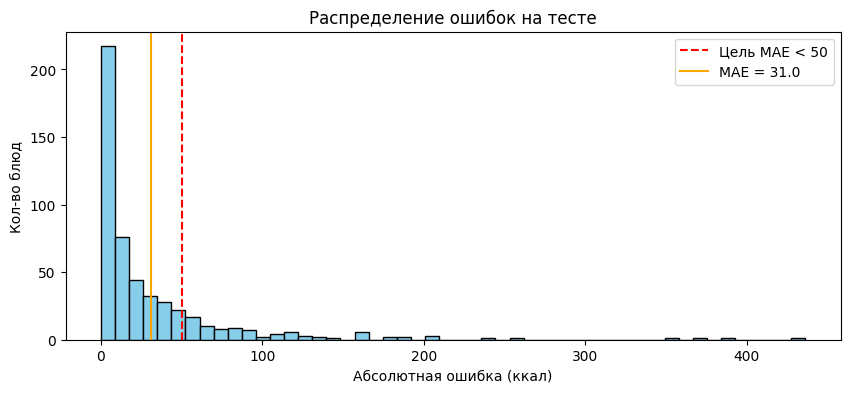

In [25]:
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt

from scripts.config import Config
from scripts.utils import MultiModalCalorieModel, load_checkpoint

cfg = Config()
device = torch.device(cfg.DEVICE)

# --- загрузка чекпоинта (state_dict + статистики + конфиг) ---
ckpt = load_checkpoint(cfg.MODEL_SAVE_PATH, device)
t_mean, t_std = ckpt['target_mean'], ckpt['target_std']
m_mean, m_std = ckpt['mass_mean'],   ckpt['mass_std']

model_eval = MultiModalCalorieModel(
    image_model_name=ckpt['config']['IMAGE_MODEL'],
    text_model_name=ckpt['config']['TEXT_MODEL'],
    hidden_dim=ckpt['config']['HIDDEN_DIM'],
).to(device)
model_eval.load_state_dict(ckpt['model_state_dict'])
model_eval.eval()
print(f"[OK] Загружен чекпоинт эпохи {ckpt['epoch']} "
      f"(val cal MAE={ckpt['best_val_calories_mae']:.2f})")

# --- инференс на TEST (единственный раз за проект) ---
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=1, shuffle=False)

all_preds, all_targets, all_masses = [], [], []
with torch.no_grad():
    for batch in test_loader:
        images     = batch['image'].to(device)
        mass_norm  = batch['mass'].to(device)
        targets    = batch['target'].to(device)
        text_inputs = {k: v.to(device) for k, v in batch['text'].items()}

        out = model_eval(images, text_inputs, mass_norm)

        pred_density = out.item()     * t_std + t_mean
        true_density = targets.item() * t_std + t_mean
        true_mass    = mass_norm.item()* m_std + m_mean

        all_preds.append(pred_density * true_mass / 100)
        all_targets.append(true_density * true_mass / 100)
        all_masses.append(true_mass)

df_preds = pd.DataFrame({
    'dish_id':       test_dataset.df['dish_id'].values,
    'pred_calories': all_preds,
    'true_calories': all_targets,
    'true_mass':     all_masses,
})
df_preds['error'] = (df_preds['true_calories'] - df_preds['pred_calories']).abs()

final_mae = df_preds['error'].mean()
print(f"\n🎯 ФИНАЛЬНЫЙ MAE НА TEST: {final_mae:.2f} ккал")
print("✅ ЦЕЛЬ ДОСТИГНУТА (MAE < 50)" if final_mae < 50 else "⚠️ MAE >= 50")
print(f"Медиана ошибки: {df_preds['error'].median():.2f} ккал")
print(f"90-й процентиль ошибки: {df_preds['error'].quantile(0.9):.2f} ккал")

# --- гистограмма ошибок ---
plt.figure(figsize=(10, 4))
plt.hist(df_preds['error'], bins=50, color='skyblue', edgecolor='black')
plt.axvline(50, color='red', ls='--', label='Цель MAE < 50')
plt.axvline(final_mae, color='orange', ls='-', label=f'MAE = {final_mae:.1f}')
plt.legend()
plt.title('Распределение ошибок на тесте')
plt.xlabel('Абсолютная ошибка (ккал)')
plt.ylabel('Кол-во блюд')
plt.show()

## 5.2. Топ-5 худших предсказаний

Выводим пять блюд с самой большой абсолютной ошибкой: фото, ингредиенты,
реальные и предсказанные калории. Это нужно, чтобы понять, на каких типах
блюд модель ошибается сильнее всего.

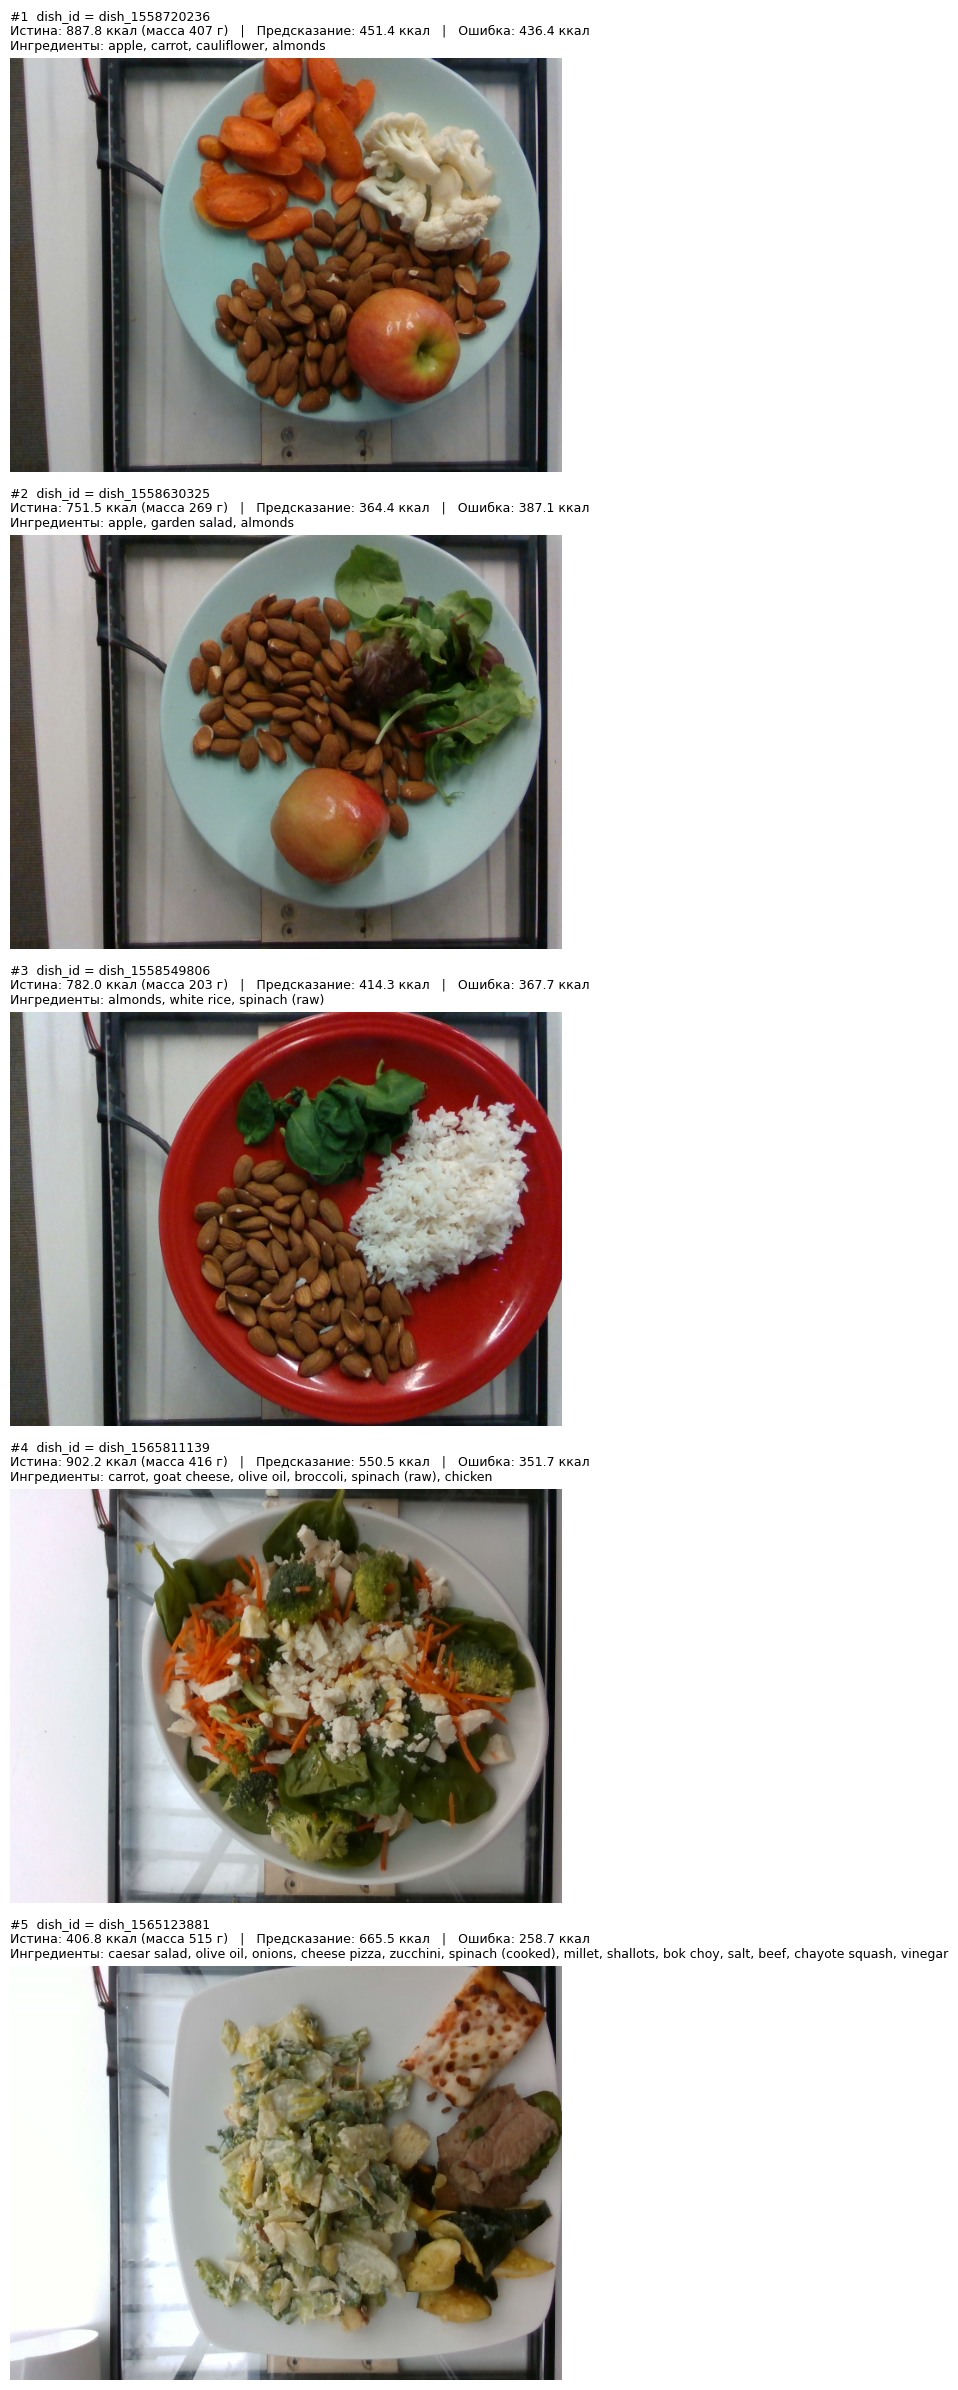


=== ТОП-5 худших предсказаний ===
        dish_id  true_calories  pred_calories  error  true_mass
dish_1558720236          887.8          451.4  436.4      407.0
dish_1558630325          751.5          364.4  387.1      269.0
dish_1558549806          782.0          414.3  367.7      203.0
dish_1565811139          902.2          550.5  351.7      416.0
dish_1565123881          406.8          665.5  258.7      515.0


In [26]:
import matplotlib.pyplot as plt
from PIL import Image

# подтягиваем текст ингредиентов и массу из исходной таблицы
ingr_lookup = dish.set_index('dish_id')[['ingredients_clean', 'total_mass', 'total_calories']]

top5 = df_preds.nlargest(5, 'error').reset_index(drop=True)

fig, axes = plt.subplots(5, 1, figsize=(14, 24))
for i, row in top5.iterrows():
    ax = axes[i]
    dish_id = row['dish_id']

    # Берем картинку из локальной папки, куда мы всё распаковали
    img_path = f"/content/images/{dish_id}/rgb.png"
    try:
        img = Image.open(img_path).convert('RGB')
        ax.imshow(img)
    except FileNotFoundError:
        ax.text(0.5, 0.5, f"Нет изображения\n{img_path}",
                ha='center', va='center', fontsize=10)
        ax.set_facecolor('#eeeeee')

    ingr_text = ingr_lookup.loc[dish_id, 'ingredients_clean']
    if isinstance(ingr_text, str) and len(ingr_text) > 240:
        ingr_text = ingr_text[:240] + "..."

    title = (
        f"#{i+1}  dish_id = {dish_id}\n"
        f"Истина: {row['true_calories']:.1f} ккал (масса {row['true_mass']:.0f} г)   |   "
        f"Предсказание: {row['pred_calories']:.1f} ккал   |   Ошибка: {row['error']:.1f} ккал\n"
        f"Ингредиенты: {ingr_text}"
    )
    ax.set_title(title, fontsize=9, loc='left')
    ax.axis('off')

plt.tight_layout()
plt.show()

# --- сводная таблица ---
print("\n=== ТОП-5 худших предсказаний ===")
print(
    top5[['dish_id', 'true_calories', 'pred_calories', 'error', 'true_mass']]
    .assign(
        true_calories=lambda d: d.true_calories.round(1),
        pred_calories=lambda d: d.pred_calories.round(1),
        error=lambda d: d.error.round(1),
        true_mass=lambda d: d.true_mass.round(0),
    )
    .to_string(index=False)
)

## 5.3. Анализ топ-5 худших предсказаний

Анализ самых больших ошибок (Топ-5) выявил четкую закономерность. 4 из 5 блюд с самой высокой ошибкой — это блюда, содержащие **высококалорийные ингредиенты с малой массой** (миндаль, оливковое масло, сыр).

**Основные причины ошибок:**

1. **Недооценка скрытой калорийности (примеры #1, #2, #3, #4).**
   На фотографиях №1, №2 и №3 модель видит яблоко, салат или рис, но не осознает объема горсти миндаля (который имеет плотность ~600 ккал/100г). В результате модель предсказывает 360–450 ккал, тогда как реальная калорийность превышает 750 ккал. Визуально горсть орехов не выглядит на 400+ ккал, но по факту это очень плотная энергия.
   В примере №4 (салат с козьим сыром и маслом) та же проблема: заправка и сыр дают огромный прирост калорий, который модель не смогла оценить по фото.

2. **Переоценка из-за длинного списка ингредиентов (пример #5).**
   Блюдо `dish_1565123881` содержит длинный список тяжелых ингредиентов (пицца, свинина, плов, миллет). Модель, опираясь на текст, выдала завышенное предсказание (665 ккал), хотя фактическая масса порции и пропорции ингредиентов дали всего 406 ккал. Модель "перестраховалась" из-за текстового описания.

3. **Нетипичные порции.**
   В целом, все эти блюда имеют массу от 200 до 500 г, но сочетают в себе легкие объемные продукты (яблоки, зелень) с экстремально калорийными (орехи, масло).

**Вывод и план улучшения:**
Модель отлично справляется со стандартными блюдами (медиана ошибки всего 13 ккал), но испытывает трудности с оценкой объема мелких высококалорийных компонентов (орехи, масла). Для улучшения можно добавить в обучение больше примеров с орехами и заправками, а также попробовать добавить в модель признак «количество ингредиентов» или их текстовые веса (если они есть в датасете).

In [1]:
import shutil
import os

# Папка проекта на Google Диске
project_dir = '/content/drive/MyDrive/calorie-project'
# Временная папка, куда соберем только то, что нужно для сдачи
temp_dir = '/content/for_github'

# Очищаем временную папку, если она была
if os.path.exists(temp_dir):
    shutil.rmtree(temp_dir)
os.makedirs(temp_dir)

# Копируем нужные файлы
# 1. Папка со скриптами
if os.path.exists(os.path.join(project_dir, 'scripts')):
    shutil.copytree(os.path.join(project_dir, 'scripts'), os.path.join(temp_dir, 'scripts'))

# 2. Ноутбук
if os.path.exists(os.path.join(project_dir, 'notebook.ipynb')):
    shutil.copy(os.path.join(project_dir, 'notebook.ipynb'), os.path.join(temp_dir, 'notebook.ipynb'))

# 3. Текстовые файлы (README, requirements)
for filename in ['README.md', 'requirements.txt']:
    if os.path.exists(os.path.join(project_dir, filename)):
        shutil.copy(os.path.join(project_dir, filename), os.path.join(temp_dir, filename))

# 4. Веса модели
if os.path.exists(os.path.join(project_dir, 'best_calorie_model.pth')):
    shutil.copy(os.path.join(project_dir, 'best_calorie_model.pth'), os.path.join(temp_dir, 'best_calorie_model.pth'))

# Запаковываем все в zip-архив
print("Создаю архив...")
shutil.make_archive('/content/calorie_project_submit', 'zip', temp_dir)
print("Архив готов: /content/calorie_project_submit.zip")

Создаю архив...
Архив готов: /content/calorie_project_submit.zip
